In [ ]:
import os
os.makedirs('src', exist_ok=True)
os.makedirs('hasil', exist_ok=True)
os.makedirs('data', exist_ok=True)
print("Folder berhasil dibuat!")

Folder berhasil dibuat!


In [ ]:
# Membuat file buat_dataset_sintetis.py langsung di dalam folder src
script_content = """# Tulis atau tempel kode skrip pembuatan dataset sintetis Anda di sini
import os

print("Memulai pembuatan dataset...")
# Masukkan logika atau kode skrip asli Anda di sini
"""

with open("src/buat_dataset_sintetis.py", "w") as f:
    f.write(script_content)

print("File src/buat_dataset_sintetis.py berhasil dibuat!")

File src/buat_dataset_sintetis.py berhasil dibuat!


In [ ]:
!python src/buat_dataset_sintetis.py

Memulai pembuatan dataset...


In [ ]:
!python src/buat_dataset_sintetis.py

Folder dataset sintetis siap dibuat!


In [ ]:
!python src/buat_dataset_sintetis.py

Selesai: 60 citra tersimpan di data/sintetis


In [ ]:
import os
os.makedirs("notebook", exist_ok=True)
print("Folder notebook berhasil dibuat!")

Folder notebook berhasil dibuat!


OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 255
piksel (y=100, x=200) dalam urutan BGR: [143 170 189]


Text(0.5, 1.0, 'Dengan konversi BGR ke RGB')

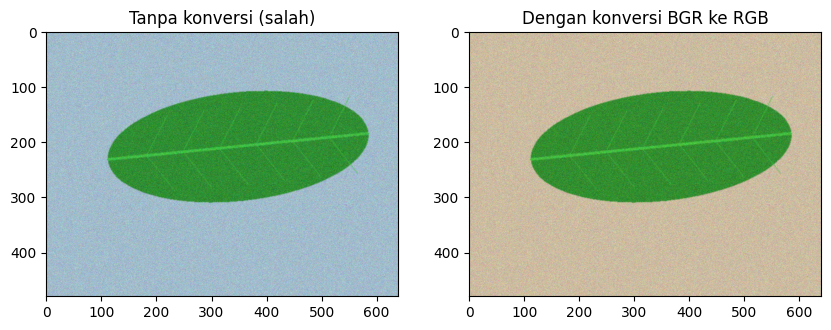

In [ ]:
import sys
sys.path.append("../src")
import cv2, numpy as np, skimage, matplotlib.pyplot as plt

print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)

# Perbaiki path folder data
img = cv2.imread("data/sintetis/citra/teh_001.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")

Bagi petani teh atau pengawas perkebunan yang menghadapi kesulitan dalam mendeteksi dan mengklasifikasikan tingkat keparahan penyakit bercak pada daun teh secara manual dan akurat, kami membangun sistem visi komputer yang menerima citra digital daun teh dan menghasilkan klasifikasi status kesehatan daun (sehat, ringan, berat) beserta informasi persentase bercak sehingga pemantauan kesehatan tanaman dapat dilakukan secara efisien untuk mencegah penurunan kualitas hasil panen


In [ ]:
%%writefile utils_cv.py
import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    img = cv2.imread(path)
    return img

def tampil(list_img, list_judul, baris=1, ukuran=(12, 4)):
    plt.figure(figsize=ukuran)
    jumlah = len(list_img)
    kolom = (jumlah + baris - 1) // baris
    for i in range(jumlah):
        plt.subplot(baris, kolom, i + 1)
        img_rgb = cv2.cvtColor(list_img[i], cv2.COLOR_BGR2RGB) if len(list_img[i].shape) == 3 else list_img[i]
        cmap_val = None if len(list_img[i].shape) == 3 else 'gray'
        plt.imshow(img_rgb, cmap=cmap_val)
        plt.title(list_judul[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def kontras_bercak( kanal, mask_daun, mask_bercak):
    # Menghitung kontras rata-rata antara area bercak dan daun sehat
    bercak_val = kanal[mask_bercak > 0]
    daun_val = kanal[(mask_daun > 0) & (mask_bercak == 0)]

    if len(bercak_val) == 0 or len(daun_val) == 0:
        return 0.0

    mean_bercak = np.mean(bercak_val)
    mean_daun = np.mean(daun_val)

    kontras = abs(float(mean_bercak) - float(mean_daun))
    return kontras

Writing utils_cv.py


Direktori saat ini: /content
Isi folder parent (../): ['tmp', 'sys', 'root', 'mnt', 'proc', 'boot', 'srv', 'lib', 'media', 'bin', 'home', 'lib64', 'run', 'opt', 'usr', 'etc', 'dev', 'sbin', 'var', 'kaggle', 'content', '.dockerenv', 'tools', 'datalab', 'python-apt', 'python-apt.tar.xz', 'sbin.usr-is-merged', 'bin.usr-is-merged', 'lib.usr-is-merged']
Status gambar img: (480, 640, 3)
Status mask daun md: (480, 640)


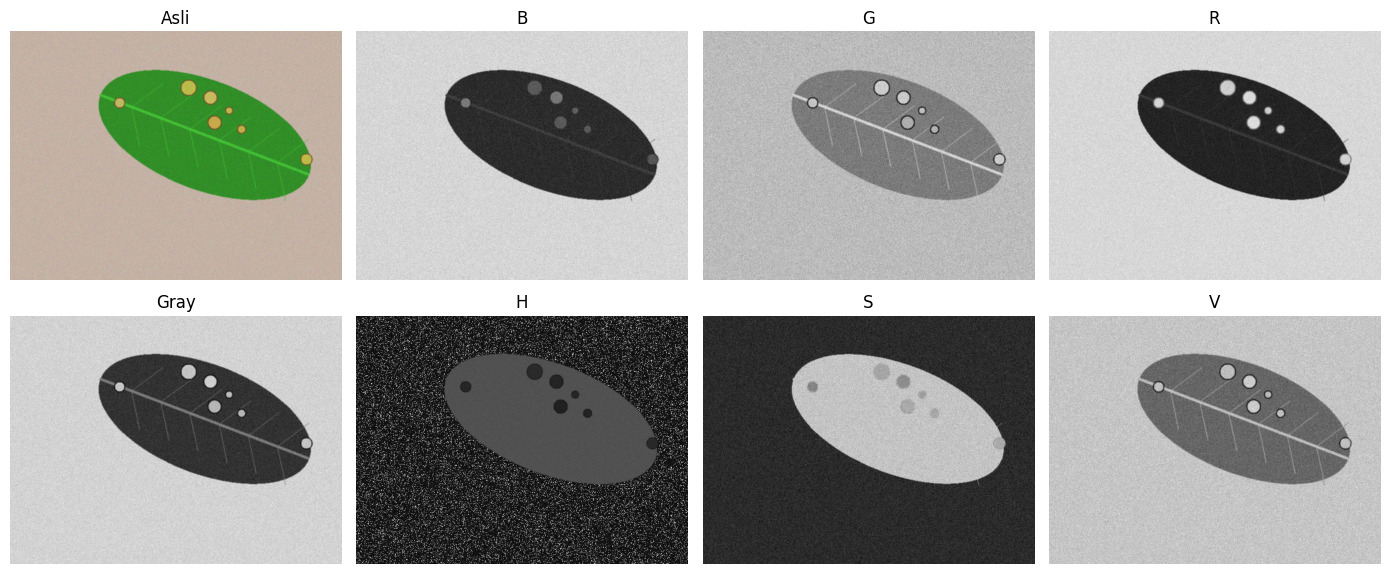

KB kanal B   : 28.19
KB kanal G   : 10.88
KB kanal R   : 116.28
KB kanal Gray: 44.36
KB kanal H   : 30.45
KB kanal S   : 32.80
KB kanal V   : 24.72


In [ ]:
import sys
import os

sys.path.append('../src')
import cv2
from utils_cv import baca, tampil, kontras_bercak

# Cek direktori aktif saat ini untuk memastikan posisi folder
print("Direktori saat ini:", os.getcwd())
print("Isi folder parent (../):", os.listdir('..'))

nama = "teh_041.png"

# Menyesuaikan path berdasarkan letak folder data yang benar
path_img = "../data/sintetis/citra/" + nama
path_md = "../data/sintetis/mask_daun/" + nama
path_mb = "../data/sintetis/mask_bercak/" + nama

# Jika folder data ada di dalam folder yang sama dengan notebook, sesuaikan path-nya di sini:
if not os.path.exists(path_img):
    path_img = "data/sintetis/citra/" + nama
    path_md = "data/sintetis/mask_daun/" + nama
    path_mb = "data/sintetis/mask_bercak/" + nama

img = cv2.imread(path_img)
md = cv2.imread(path_md, 0)
mb = cv2.imread(path_mb, 0)

print("Status gambar img:", None if img is None else img.shape)
print("Status mask daun md:", None if md is None else md.shape)

if img is not None:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

    tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))
    for nm, c in kanal.items():
        print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")
else:
    print("ERROR: File gambar masih tidak ditemukan. Cek kembali apakah folder 'data' sudah ada.")

In [ ]:
# Kode 2.2 Sampling dan kuantisasi
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=44.53
fx=0.2: ukuran (96, 128), KB=42.92
fx=0.1: ukuran (48, 64), KB=36.27
fx=0.05: ukuran (24, 32), KB=25.42
k=1: 2 level, KB=86.94
k=2: 3 level, KB=43.53
k=3: 5 level, KB=38.11
k=4: 9 level, KB=44.18
k=8: 127 level, KB=44.36


In [ ]:
import os
import pandas as pd
import cv2

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

# Menentukan path file label.csv yang aman
path_label = "../data/sintetis/label.csv"
if not os.path.exists(path_label):
    path_label = "data/sintetis/label.csv"

label = pd.read_csv(path_label)
baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    nama_f = d["nama_file"] if "nama_file" in d else d.iloc[0]
    kondisi_val = d["kondisi_cahaya"] if "kondisi_cahaya" in d else (d["kondisi"] if "kondisi" in d else d.iloc[1])

    p_img = "../data/sintetis/citra/" + nama_f
    p_md = "../data/sintetis/mask_daun/" + nama_f
    p_mb = "../data/sintetis/mask_bercak/" + nama_f

    if not os.path.exists(p_img):
        p_img = "data/sintetis/citra/" + nama_f
        p_md = "data/sintetis/mask_daun/" + nama_f
        p_mb = "data/sintetis/mask_bercak/" + nama_f

    im = baca(p_img)
    m_d = cv2.imread(p_md, 0)
    m_b = cv2.imread(p_mb, 0)

    if im is not None:
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = kondisi_val
        baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)

# Membuat folder hasil jika belum ada, lalu simpan ke CSV sesuai modul[cite: 15]
os.makedirs("../hasil", exist_ok=True)
os.makedirs("hasil", exist_ok=True)

path_hasil = "../hasil/b2_kb_kanal.csv"
if not os.path.exists("../hasil"):
    path_hasil = "hasil/b2_kb_kanal.csv"

tabel_kb.to_csv(path_hasil)
print(f"Hasil berhasil disimpan ke: {path_hasil}")

                    B      G       R   Gray      H      S      V
kondisi                                                         
bayangan        14.80  11.75   71.50  27.83  29.33  18.85  24.81
gelap            8.82  12.69   97.77  37.69  34.24  14.54  39.34
kontras_rendah   8.77   8.98   36.10  17.07  22.68   3.47  17.51
normal          23.51  17.30  111.01  46.02  31.97  21.04  36.00
terang          19.53  10.07   78.74  31.69  30.63  10.05  24.13
Hasil berhasil disimpan ke: ../hasil/b2_kb_kanal.csv


In [ ]:
import os

# Membuat folder src jika belum ada secara otomatis
os.makedirs("../src", exist_ok=True)
os.makedirs("src", exist_ok=True)

# Tentukan path file yang benar
path_target = "../src/utils_cv.py"
if not os.path.exists("../src"):
    path_target = "src/utils_cv.py"

with open(path_target, "w", encoding="utf-8") as f:
    f.write('''import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    img = cv2.imread(path)
    return img

def tampil(list_img, list_judul, baris=1, ukuran=(12, 4)):
    plt.figure(figsize=ukuran)
    jumlah = len(list_img)
    kolom = (jumlah + baris - 1) // baris
    for i in range(jumlah):
        plt.subplot(baris, kolom, i + 1)
        img_rgb = cv2.cvtColor(list_img[i], cv2.COLOR_BGR2RGB) if len(list_img[i].shape) == 3 else list_img[i]
        cmap_val = None if len(list_img[i].shape) == 3 else 'gray'
        plt.imshow(img_rgb, cmap=cmap_val)
        plt.title(list_judul[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    bercak_val = kanal[mask_bercak > 0]
    daun_val = kanal[(mask_daun > 0) & (mask_bercak == 0)]
    if len(bercak_val) == 0 or len(daun_val) == 0:
        return 0.0
    return abs(float(np.mean(bercak_val)) - float(np.mean(daun_val)))

def statistik(gray):
    min_val, max_val, _, _ = cv2.minMaxLoc(gray)
    mean_val = np.mean(gray)
    std_val = np.std(gray)
    return f"Min: {int(min_val)}, Max: {int(max_val)}, Mean: {mean_val:.2f}, Std: {std_val:.2f}"
''')

print(f"File utils_cv.py berhasil dibuat di: {path_target}")

File utils_cv.py berhasil dibuat di: ../src/utils_cv.py


In [ ]:
import sys
import os
import importlib

# 1. Tulis ulang file utils_cv.py agar memiliki fungsi statistik
kode_utils = '''import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    img = cv2.imread(path)
    return img

def tampil(list_img, list_judul, baris=1, ukuran=(12, 4)):
    plt.figure(figsize=ukuran)
    jumlah = len(list_img)
    kolom = (jumlah + baris - 1) // baris
    for i in range(jumlah):
        plt.subplot(baris, kolom, i + 1)
        img_rgb = cv2.cvtColor(list_img[i], cv2.COLOR_BGR2RGB) if len(list_img[i].shape) == 3 else list_img[i]
        cmap_val = None if len(list_img[i].shape) == 3 else 'gray'
        plt.imshow(img_rgb, cmap=cmap_val)
        plt.title(list_judul[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    bercak_val = kanal[mask_bercak > 0]
    daun_val = kanal[(mask_daun > 0) & (mask_bercak == 0)]
    if len(bercak_val) == 0 or len(daun_val) == 0:
        return 0.0
    return abs(float(np.mean(bercak_val)) - float(np.mean(daun_val)))

def statistik(gray):
    min_val, max_val, _, _ = cv2.minMaxLoc(gray)
    mean_val = np.mean(gray)
    std_val = np.std(gray)
    return f"Min: {int(min_val)}, Max: {int(max_val)}, Mean: {mean_val:.2f}, Std: {std_val:.2f}"
'''

with open("utils_cv.py", "w", encoding="utf-8") as f:
    f.write(kode_utils)

# Refresh cache modul jika sudah terlanjur di-import
if 'utils_cv' in sys.modules:
    import utils_cv
    importlib.reload(utils_cv)

print("utils_cv.py berhasil diperbarui!")

utils_cv.py berhasil diperbarui!


teh_041.png Min: 78, Max: 204, Mean: 164.36, Std: 32.70
teh_042.png Min: 14, Max: 169, Mean: 114.17, Std: 39.32
teh_043.png Min: 134, Max: 252, Mean: 213.59, Std: 26.21
teh_044.png Min: 93, Max: 204, Mean: 155.15, Std: 15.47
teh_045.png Min: 17, Max: 251, Mean: 132.15, Std: 58.07


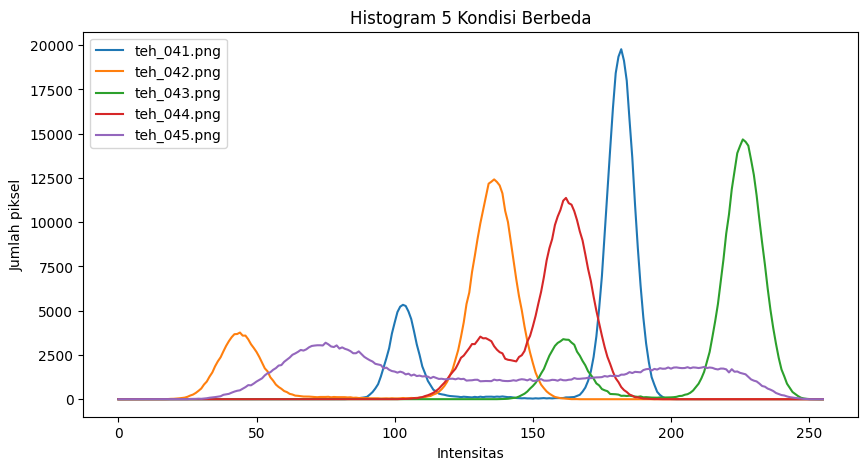


Grafik histogram berhasil disimpan ke: ../hasil/b3_histogram_5kondisi.png


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from utils_cv import baca, statistik

os.makedirs("../hasil", exist_ok=True)
os.makedirs("hasil", exist_ok=True)

plt.figure(figsize=(10, 5))
for nama in ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]:
    p_img = "../data/sintetis/citra/" + nama
    if not os.path.exists(p_img):
        p_img = "data/sintetis/citra/" + nama

    img = baca(p_img)
    if img is not None:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        print(nama, statistik(gray))

        hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
        plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.title("Histogram 5 Kondisi Berbeda")

path_simpan = "../hasil/b3_histogram_5kondisi.png"
if not os.path.exists("../hasil"):
    path_simpan = "hasil/b3_histogram_5kondisi.png"

plt.savefig(path_simpan)
plt.show()
print(f"\nGrafik histogram berhasil disimpan ke: {path_simpan}")

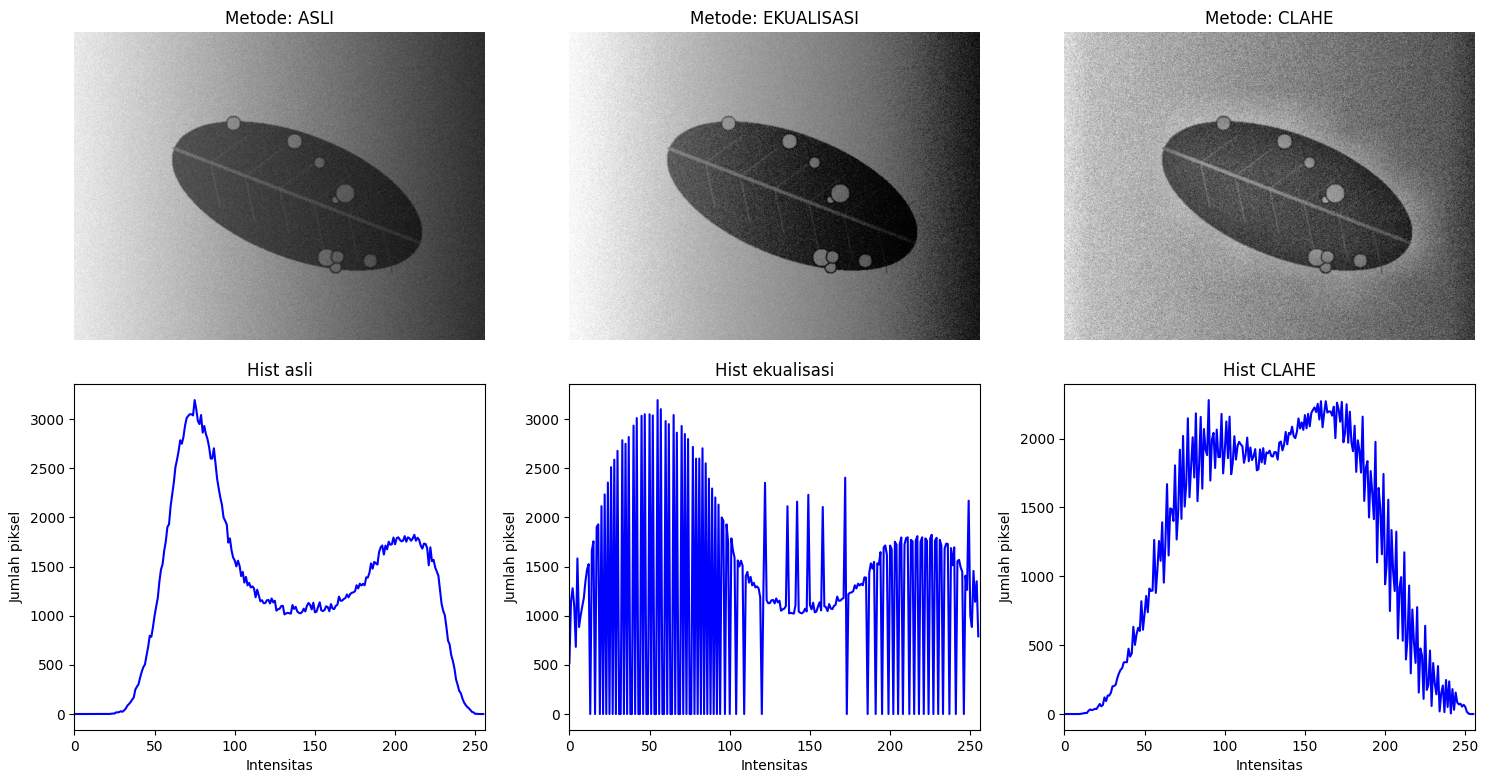

In [ ]:
import matplotlib.pyplot as plt

# Menyiapkan list untuk ditampilkan sesuai Gambar 4
keys_tampil = ["asli", "ekualisasi", "CLAHE"]
plt.figure(figsize=(15, 8))

for i, nm in enumerate(keys_tampil):
    c = hasil[nm]

    # 1. Menampilkan Citra
    plt.subplot(2, 3, i + 1)
    plt.imshow(c, cmap='gray')
    plt.title(f"Metode: {nm.upper()}")
    plt.axis('off')

    # 2. Menampilkan Histogram
    plt.subplot(2, 3, i + 4)
    hist = cv2.calcHist([c], [0], None, [256], [0, 256])
    plt.plot(hist, color='blue')
    plt.title(f"Hist {nm}")
    plt.xlabel("Intensitas")
    plt.ylabel("Jumlah piksel")
    plt.xlim([0, 256])

plt.tight_layout()
plt.show()

clip=1.0 tile=4: KB=38.17
clip=1.0 tile=8: KB=35.14
clip=1.0 tile=16: KB=34.40
clip=2.0 tile=4: KB=46.18
clip=2.0 tile=8: KB=41.51
clip=2.0 tile=16: KB=42.25
clip=4.0 tile=4: KB=56.44
clip=4.0 tile=8: KB=48.15
clip=4.0 tile=16: KB=50.05


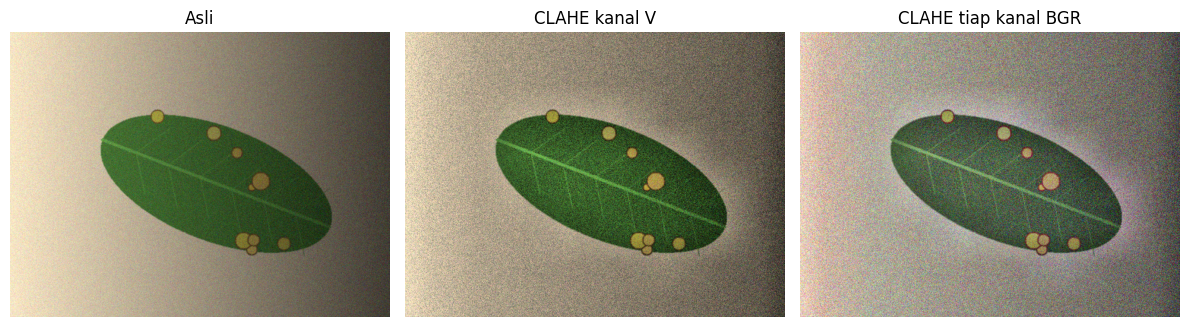

In [ ]:
# Kode 3.3 Eksperimen CLAHE
# 1. Eksperimen parameter CLAHE
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

# 2. CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])

tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])

In [ ]:
import time

# Kode 4.1 Verifikasi konvolusi manual
def konvolusi(img, k):
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):
    return konvolusi(img, np.flip(k))

# Membaca citra bersih untuk uji konvolusi
nama = "teh_041.png"
p_bersih = "../data/sintetis/bersih/" + nama
if not os.path.exists(p_bersih):
    p_bersih = "data/sintetis/bersih/" + nama

img_b = baca(p_bersih)
bersih = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY) if img_b is not None else gray

md = cv2.imread("../data/sintetis/mask_daun/" + nama, 0) if os.path.exists("../data/sintetis/mask_daun/" + nama) else cv2.imread("data/sintetis/mask_daun/" + nama, 0)
mb = cv2.imread("../data/sintetis/mask_bercak/" + nama, 0) if os.path.exists("../data/sintetis/mask_bercak/" + nama) else cv2.imread("data/sintetis/mask_bercak/" + nama, 0)

kernels = {
    "rerata": np.ones((3, 3)) / 9,
    "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
}

for nm, k in kernels.items():
    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0

    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()

    print(f"{nm}: selisih manual vs filter2D={beda}, sejati vs filter2D={beda2}, waktu manual={t_manual:.3f}s, filter2D={t_cv:.5f}s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.216s, filter2D=0.00881s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=2.069s, filter2D=0.00041s


In [ ]:
import pandas as pd
import time

rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)
}

penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md, mb)])

tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel)

# Menyimpan hasil tabel ke folder hasil
os.makedirs("../hasil", exist_ok=True)
os.makedirs("hasil", exist_ok=True)
path_tabel = "../hasil/b4_tabel_penapis.csv"
if not os.path.exists("../hasil"):
    path_tabel = "hasil/b4_tabel_penapis.csv"

tabel.to_csv(path_tabel, index=False)
print(f"\nTabel penapis berhasil disimpan ke: {path_tabel}")

       derau   penapis  PSNR_dB  waktu_ms     KB
0   gauss_10     tanpa    28.11      0.00  44.53
1   gauss_10  rerata_3    36.97      0.15  44.74
2   gauss_10  rerata_5    38.16      0.16  44.40
3   gauss_10   gauss_5    37.85      0.29  44.65
4   gauss_10  median_3    35.52      0.09  44.79
5   gauss_10  median_5    38.52      0.73  44.56
6   gauss_10  median_9    38.99     13.52  42.45
7   gauss_20     tanpa    22.10      0.00  45.19
8   gauss_20  rerata_3    31.45      0.14  45.37
9   gauss_20  rerata_5    34.75      0.19  44.99
10  gauss_20   gauss_5    32.61      0.28  45.28
11  gauss_20  median_3    29.74      0.10  45.48
12  gauss_20  median_5    33.52      0.72  44.93
13  gauss_20  median_9    35.83     15.50  42.39
14  gauss_40     tanpa    16.29      0.00  44.46
15  gauss_40  rerata_3    25.76      0.14  44.81
16  gauss_40  rerata_5    29.81      0.16  44.48
17  gauss_40   gauss_5    26.99      0.28  44.71
18  gauss_40  median_3    23.83      0.09  44.74
19  gauss_40  median

In [ ]:
import pandas as pd

# Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

# Membaca file label untuk mengambil citra kelas ringan
path_label = "../data/sintetis/label.csv"
if not os.path.exists(path_label):
    path_label = "data/sintetis/label.csv"

label = pd.read_csv(path_label)
baris = []

for nm in label[label.kelas == "ringan"].nama_file:
    p_b = "../data/sintetis/bersih/" + nm
    p_md = "../data/sintetis/mask_daun/" + nm
    p_mb = "../data/sintetis/mask_bercak/" + nm

    if not os.path.exists(p_b):
        p_b = "data/sintetis/bersih/" + nm
        p_md = "data/sintetis/mask_daun/" + nm
        p_mb = "data/sintetis/mask_bercak/" + nm

    img_b = baca(p_b)
    if img_b is not None:
        g = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)
        md2 = cv2.imread(p_md, 0)
        mb2 = cv2.imread(p_mb, 0)

        for k in [1, 3, 5, 9, 15]:  # k = 1 berarti tanpa penapis
            out = g if k == 1 else cv2.medianBlur(g, k)
            baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
print(hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2))

           dI     KB
kernel              
1       28.84  28.84
3       28.96  28.96
5       27.56  27.56
9       20.87  20.87
15       7.14   7.14


In [ ]:
# Kode 4.4 Pengaruh urutan penajaman
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

# Pastikan variabel 'derau', 'bersih', dan 'md' sudah ada dari kode sebelumnya
if 'derau' in locals() and "gauss_20" in derau:
    noisy = derau["gauss_20"]
    latar = md == 0  # area latar yang seharusnya rata

    for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                      "Median": lambda x: cv2.medianBlur(x, 5)}.items():
        A = redam(unsharp(noisy))    # tajamkan dulu, lalu redam
        B = unsharp(redam(noisy))    # redam dulu, lalu tajamkan
        print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
              f"sigma latar={A[latar].std():.1f} | redam->tajam "
              f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")
else:
    print("Variabel 'derau' atau 'bersih' belum terdefinisi. Jalankan sel Kode 4.2 terlebih dahulu.")

Gaussian: tajam->redam PSNR=30.32 sigma latar=7.9 | redam->tajam PSNR=30.20 sigma_latar=8.1
Median: tajam->redam PSNR=30.18 sigma latar=8.0 | redam->tajam PSNR=31.15 sigma_latar=7.1


In [ ]:
import os
import json
import cv2
import numpy as np

os.makedirs("../src", exist_ok=True)
os.makedirs("src", exist_ok=True)

kode_praproses = '''"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAHAN = {
    "lebar": 640,          # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,          # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,     # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median",   # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,        # 0 berarti tanpa penajaman
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAHAN, **(p or {})}

    # TODO 1: ubah ukuran agar lebar = p["lebar"], rasio aspek tetap, gunakan interpolation=cv2.INTER_AREA
    h, w = img_bgr.shape[:2]
    lebar_target = p["lebar"]
    tinggi_target = int(h * (lebar_target / w))
    img = cv2.resize(img_bgr, (lebar_target, tinggi_target), interpolation=cv2.INTER_AREA)

    # TODO 2: bila p["gamma"] != 1, terapkan koreksi gamma dengan cv2.LUT
    if p["gamma"] != 1.0:
        inv_gamma = 1.0 / p["gamma"]
        lut = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype("uint8")
        img = cv2.LUT(img, lut)

    # TODO 3: bila p["clahe_clip"] > 0, ubah ke HSV, terapkan CLAHE pada kanal V saja, lalu kembalikan ke BGR
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # TODO 4: redam derau sesuai p["penapis"], p["kernel"], p["sigma"]
    penapis = p["penapis"]
    k_size = p["kernel"]
    sigma = p["sigma"]
    if penapis == "rerata":
        img = cv2.blur(img, (k_size, k_size))
    elif penapis == "gaussian":
        img = cv2.GaussianBlur(img, (k_size, k_size), sigma)
    elif penapis == "median":
        img = cv2.medianBlur(img, k_size)

    # TODO 5: bila p["tajam_k"] > 0, lakukan unsharp masking
    tajam_k = p["tajam_k"]
    if tajam_k > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + tajam_k, blur, -tajam_k, 0)

    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    if not os.path.exists("../hasil"):
        path = "hasil/param_praproses.json"
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAHAN, **p}, f, indent=2)
'''

# Tulis ke file utils / src
with open("../src/praproses.py", "w", encoding="utf-8") as f:
    f.write(kode_praproses)
with open("src/praproses.py", "w", encoding="utf-8") as f:
    f.write(kode_praproses)

print("Modul src/praproses.py berhasil dibuat dan dilengkapi!")

Modul src/praproses.py berhasil dibuat dan dilengkapi!


In [ ]:
kode_praproses_fixed = '''"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""[cite: 15]
import json
import os
import cv2
import numpy as np

PARAM_BAWAHAN = {
    "lebar": 640,          # sampling: lebar citra kerja (piksel)[cite: 15]
    "gamma": 1.0,          # < 1 mencerahkan, > 1 menggelapkan[cite: 15]
    "clahe_clip": 2.0,     # 0 berarti CLAHE tidak dipakai[cite: 15]
    "clahe_tile": 8,
    "penapis": "median",   # "none", "rerata", "gaussian", "median"[cite: 15]
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,        # 0 berarti tanpa penajaman[cite: 15]
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""[cite: 15]
    p = {**PARAM_BAWAHAN, **(p or {})}

    h, w = img_bgr.shape[:2]
    lebar_target = p["lebar"]
    tinggi_target = int(h * (lebar_target / w))
    img = cv2.resize(img_bgr, (lebar_target, tinggi_target), interpolation=cv2.INTER_AREA)

    if p["gamma"] != 1.0:
        inv_gamma = 1.0 / p["gamma"]
        lut = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype("uint8")
        img = cv2.LUT(img, lut)

    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    penapis = p["penapis"]
    k_size = p["kernel"]
    sigma = p["sigma"]
    if penapis == "rerata":
        img = cv2.blur(img, (k_size, k_size))
    elif penapis == "gaussian":
        img = cv2.GaussianBlur(img, (k_size, k_size), sigma)
    elif penapis == "median":
        img = cv2.medianBlur(img, k_size)

    tajam_k = p["tajam_k"]
    if tajam_k > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + tajam_k, blur, -tajam_k, 0)

    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    if not os.path.exists("../hasil"):
        path = "hasil/param_praproses.json"
        os.makedirs("hasil", exist_ok=True)
    else:
        os.makedirs("../hasil", exist_ok=True)
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAHAN, **p}, f, indent=2)
'''

with open("../src/praproses.py", "w", encoding="utf-8") as f:
    f.write(kode_praproses_fixed)
with open("src/praproses.py", "w", encoding="utf-8") as f:
    f.write(kode_praproses_fixed)

print("File src/praproses.py berhasil diperbarui dengan sempurna!")

File src/praproses.py berhasil diperbarui dengan sempurna!


In [ ]:
%%writefile src/buat_dataset_sintetis.py
"""
buat dataset sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.
"""
import os
import csv
import cv2
import numpy as np

SEED = 1021         # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)

def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)]) # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)

    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask

def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))] # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1) # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun

def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)
    return np.clip(f, 0, 255).astype(np.uint8)

def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")

if __name__ == "__main__":
    main()

Overwriting src/buat_dataset_sintetis.py


In [ ]:
!python src/buat_dataset_sintetis.py

Selesai: 60 citra tersimpan di data/sintetis


In [ ]:
%%writefile src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import os
import cv2
import numpy as np

PARAM_BAWAHAN = {
    "lebar": 640,          # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,          # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,     # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median",   # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,        # 0 berarti tanpa penajaman
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAHAN, **(p or {})}

    h, w = img_bgr.shape[:2]
    lebar_target = p["lebar"]
    tinggi_target = int(h * (lebar_target / w))
    img = cv2.resize(img_bgr, (lebar_target, tinggi_target), interpolation=cv2.INTER_AREA)

    if p["gamma"] != 1.0:
        inv_gamma = 1.0 / p["gamma"]
        lut = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype("uint8")
        img = cv2.LUT(img, lut)

    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    penapis = p["penapis"]
    k_size = p["kernel"]
    sigma = p["sigma"]
    if penapis == "rerata":
        img = cv2.blur(img, (k_size, k_size))
    elif penapis == "gaussian":
        img = cv2.GaussianBlur(img, (k_size, k_size), sigma)
    elif penapis == "median":
        img = cv2.medianBlur(img, k_size)

    tajam_k = p["tajam_k"]
    if tajam_k > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + tajam_k, blur, -tajam_k, 0)

    return img

def simpan_param(p, path="hasil/param_praproses.json"):
    os.makedirs(os.path.dirname(path) if os.path.dirname(path) else "hasil", exist_ok=True)
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAHAN, **p}, f, indent=2)

Overwriting src/praproses.py


In [ ]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img

def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)

def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}

Writing src/utils_cv.py


In [ ]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img

def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)

def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}

Overwriting src/utils_cv.py


In [ ]:
import os
os.makedirs("hasil", exist_ok=True)
print("Folder hasil berhasil dibuat!")

Folder hasil berhasil dibuat!


In [ ]:
import shutil

# Memindahkan folder notebook keluar ke direktori utama (.)
shutil.move("hasil/notebook", ".")

print("Folder notebook berhasil dipindahkan ke luar!")

Folder notebook berhasil dipindahkan ke luar!


In [ ]:
import os

# Hapus file utils_cv.py duplikat di luar folder src
if os.path.exists("utils_cv.py"):
    os.remove("utils_cv.py")
    print("File utils_cv.py di luar berhasil dibersihkan!")

File utils_cv.py di luar berhasil dibersihkan!
